In [1]:
%load_ext autoreload
%autoreload 2
    
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm
import cartopy.crs as ccrs

from cdrmip_extremes.extremes_pipeline import ExtremesPipeline
from cdrmip_extremes import (
    configs, load_pipeline, io_disk,  utils, load_raw,
    extremes, plotting as pl, stats, gwl
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
expt = '1pctCO2-cdr'

In [4]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['branch_differences_median_multimodel','gwl_period_extremes']
}

In [5]:
differences = ext_data['branch_differences_median_multimodel']
differences

{'ACCESS-ESM1-5': {'1pctCO2-cdr': {'cold': <xarray.Dataset> Size: 391kB
   Dimensions:  (gwl: 1, lat: 90, lon: 180)
   Coordinates:
     * gwl      (gwl) float64 8B 1.5
     * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
     * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
       extrema  <U4 16B ...
   Data variables:
       sigma1   (gwl, lat, lon) float64 130kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>
       sigma2   (gwl, lat, lon) float64 130kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>
       sigma3   (gwl, lat, lon) float64 130kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>,
   'heat': <xarray.Dataset> Size: 391kB
   Dimensions:  (gwl: 1, lat: 90, lon: 180)
   Coordinates:
     * gwl      (gwl) float64 8B 1.5
     * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
     * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
       extrema  <U4 16

In [6]:
ext_mon_data = ext_data['gwl_period_extremes']
ext_mon_data

{'ACCESS-ESM1-5': {'1pctCO2-cdr': {'r1i1p1f1': <xarray.Dataset> Size: 11MB
   Dimensions:  (branch: 2, gwl: 1, extrema: 2, year: 42, lat: 90, lon: 180)
   Coordinates:
     * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'
     * gwl      (gwl) float64 8B 1.5
     * extrema  (extrema) <U4 32B 'heat' 'cold'
     * year     (year) int64 336B 49 50 51 52 53 54 55 ... 267 268 269 270 271 272
     * lat      (lat) float64 720B -89.0 -87.0 -85.0 -83.0 ... 83.0 85.0 87.0 89.0
     * lon      (lon) float64 1kB 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
   Data variables:
       tas      (branch, gwl, extrema, year, lat, lon) float32 11MB dask.array<chunksize=(2, 1, 2, 42, 90, 180), meta=np.ndarray>}},
 'CanESM5': {'1pctCO2-cdr': {'r1i1p2f1': <xarray.Dataset> Size: 11MB
   Dimensions:  (branch: 2, gwl: 1, extrema: 2, year: 42, lat: 90, lon: 180)
   Coordinates:
     * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'
     * gwl      (gwl) float64 8B 1.5
     * extrema  (extrema) <U4 32B 'hea

In [7]:
src = utils.reduce_member_tree(ext_mon_data)   # the member-level gwl_period_extremes tree, as in cells 6–7
mean_diff = {e: extremes.ext_month_stat_diff(src, e, 'mean') for e in ('heat', 'cold')}

In [8]:
txx_difference = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'txx_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
)
tx90p_difference = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'tx90p_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
)
tnn_difference = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'tnn_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
)
tn10p_difference = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'tn10p_gwl_differences', 'CDRMIP', model_order=CDR_MODELS)
)

In [9]:
diffs = {var: {'diff': utils.reduce_models(d), 'agreement': stats.calc_agreement(d, expt=expt)}
         for var, d in {'txx': txx_difference, 'tx90p': tx90p_difference,
                        'tnn': tnn_difference, 'tn10p': tn10p_difference}.items()}

In [10]:
sftlf = load_raw.load_fx(['sftlf'])['sftlf'].sftlf

Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'source_id': 'ACCESS-ESM1-5', 'member_id': 'r1i1p1f1', 'table_id': 'fx', 'variable_id': ['sftlf'], 'grid_label': 'gn'}
Loading ACCESS-ESM1-5 / r1i1p1f1
Building regridder for grid (145,) x (192,)


## Correlation between tx90p and monthly extreme frequency changes?

In [11]:
tp_models = ['ACCESS-ESM1-5', 'CanESM5', 'CNRM-ESM2-1', 'MIROC-ES2L', 'UKESM1-0-LL']

def pattern_corr(a, b):
    a, b = a.reset_coords(drop=True), b.reset_coords(drop=True)   # drop extrema/percentiles etc.
    w = np.cos(np.deg2rad(b.lat)).broadcast_like(b)
    return xr.corr(a, b, dim=['lat', 'lon'], weights=w).squeeze('gwl', drop=True).compute().drop_attrs()

def tree(get):
    """{model: {expt: DataArray}} over tp_models, plus multi_model_median."""
    return utils.reduce_models({m: {expt: get(m)} for m in tp_models})

fields = {
    'heat': {
        'freq':  tree(lambda m: differences[m][expt]['heat'].to_array('threshold')),
        'mean': tree(lambda m: mean_diff['heat'][m][expt]['tas']),
        'txx':   tree(lambda m: txx_difference[m][expt]['txx']),
        'tx90p': tree(lambda m: tx90p_difference[m][expt]['tx90p']),
    },
    'cold': {
        'freq':  tree(lambda m: differences[m][expt]['cold'].to_array('threshold')),
        'mean': tree(lambda m: mean_diff['cold'][m][expt]['tas']),
        'tnn':   tree(lambda m: tnn_difference[m][expt]['tnn']),
        'tn10p': tree(lambda m: tn10p_difference[m][expt]['tn10p']),
    },
}

pairs = {'heat': [('freq', 'tx90p'), ('mean', 'txx'), ('freq', 'txx'), ('mean', 'tx90p')],
         'cold': [('freq', 'tn10p'), ('mean', 'tnn'), ('freq', 'tnn'), ('mean', 'tn10p')]}

corrs = {
    ext: {f'{a} vs {b}': {m: pattern_corr(F[a][m][expt], F[b][m][expt]) for m in F[a]}
          for a, b in pairs[ext]}
    for ext, F in fields.items()
}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

In [17]:
corrs

{'heat': {'freq vs tx90p': {'ACCESS-ESM1-5': <xarray.DataArray (threshold: 3)> Size: 24B
   array([0.6569826 , 0.71738537, 0.69545647])
   Coordinates:
     * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
   'CanESM5': <xarray.DataArray (threshold: 3)> Size: 24B
   array([0.58615582, 0.72038311, 0.68300958])
   Coordinates:
     * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
   'CNRM-ESM2-1': <xarray.DataArray (threshold: 3)> Size: 24B
   array([0.72429666, 0.8385953 , 0.83521141])
   Coordinates:
     * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
   'MIROC-ES2L': <xarray.DataArray (threshold: 3)> Size: 24B
   array([0.79912549, 0.80165096, 0.71867068])
   Coordinates:
     * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
   'UKESM1-0-LL': <xarray.DataArray (threshold: 3)> Size: 24B
   array([0.67655413, 0.78539517, 0.72358583])
   Coordinates:
     * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
   'mult

## Plot

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S4.jpg


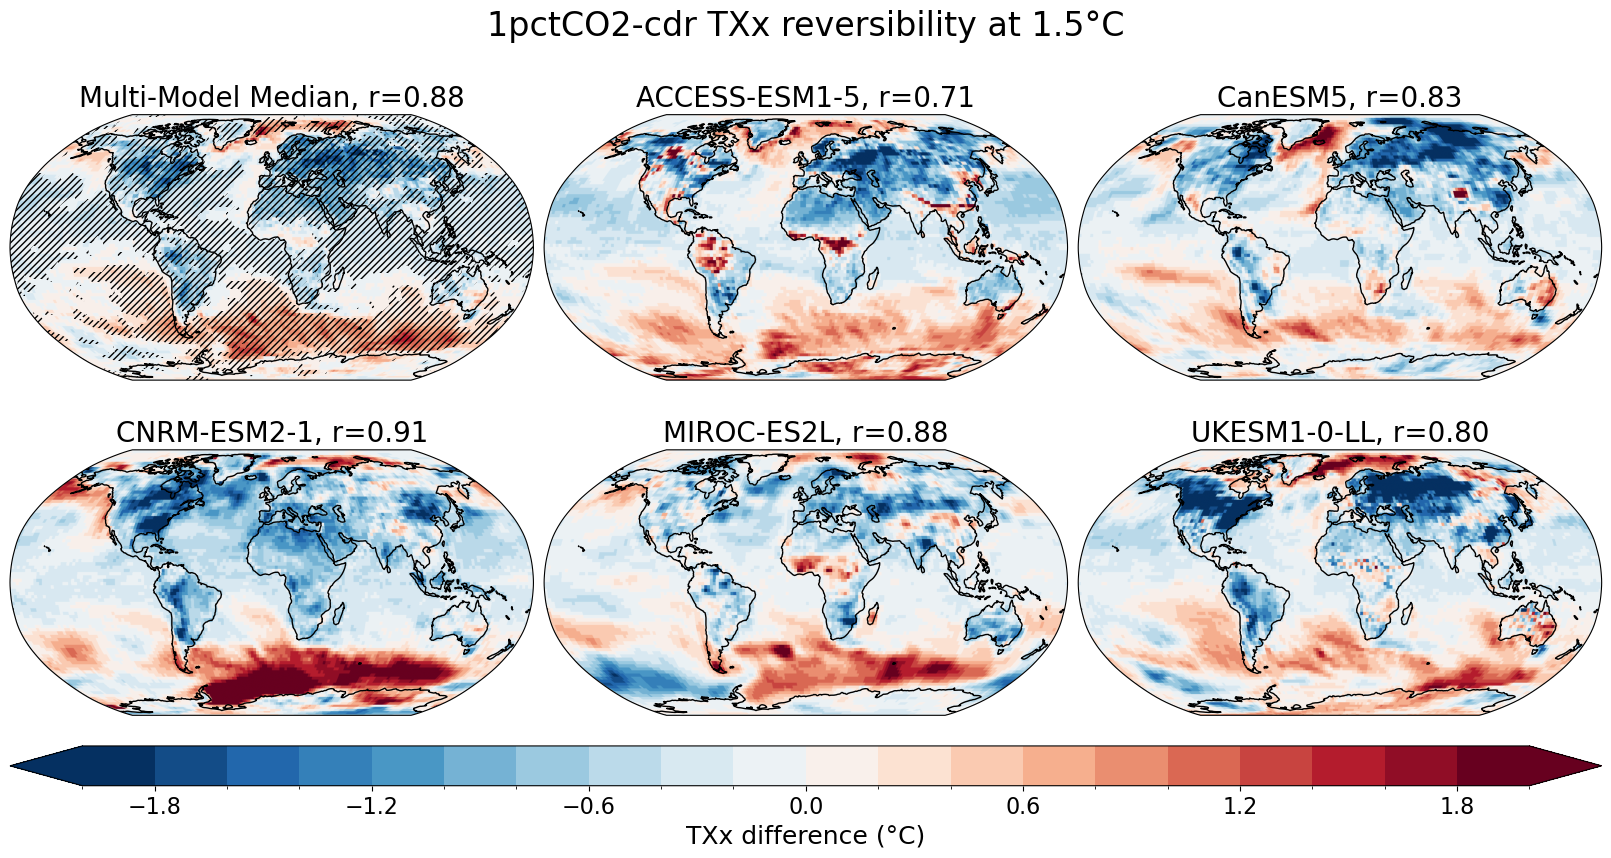

In [23]:
r = corrs['heat']['mean vs txx']
titles = {m: f"{pl.display_name(m)}, r={float(r[m]):.2f}" for m in r}

fig, axes = pl.plot_gwl_diff(
    diffs['txx']['diff'],
    '1pctCO2-cdr',
    varname='txx',
    gwl=1.5,
    levels=np.linspace(-2, 2, 21),
    cmap=cm.RdBu_r,
    agreement=diffs['txx']['agreement'],
    cbar_label='TXx difference (°C)',
    figsize=(16, 8),
    suptitle='1pctCO2-cdr TXx reversibility at 1.5°C',
    titles=titles,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S4.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S5.jpg


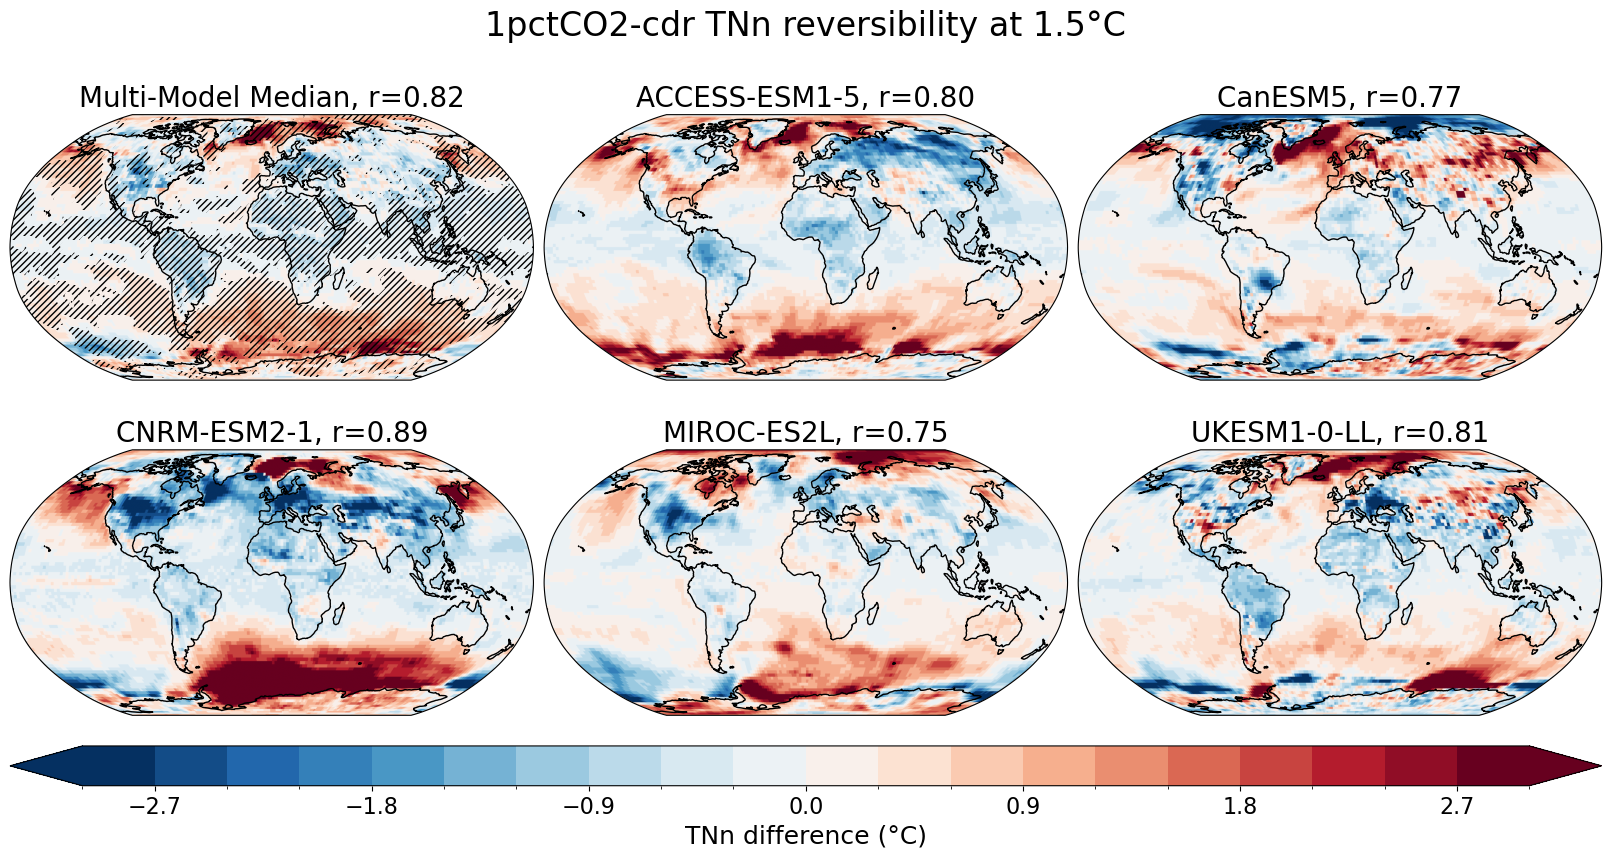

In [24]:
r = corrs['cold']['mean vs tnn']
titles = {m: f"{pl.display_name(m)}, r={float(r[m]):.2f}" for m in r}

fig, axes = pl.plot_gwl_diff(
    diffs['tnn']['diff'],
    '1pctCO2-cdr',
    varname='tnn',
    gwl=1.5,
    levels=np.linspace(-3, 3, 21),
    cmap=cm.RdBu_r,
    agreement=diffs['tnn']['agreement'],
    cbar_label='TNn difference (°C)',
    figsize=(16, 8),
    suptitle='1pctCO2-cdr TNn reversibility at 1.5°C',
    titles=titles,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S5.jpg'
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S6.jpg


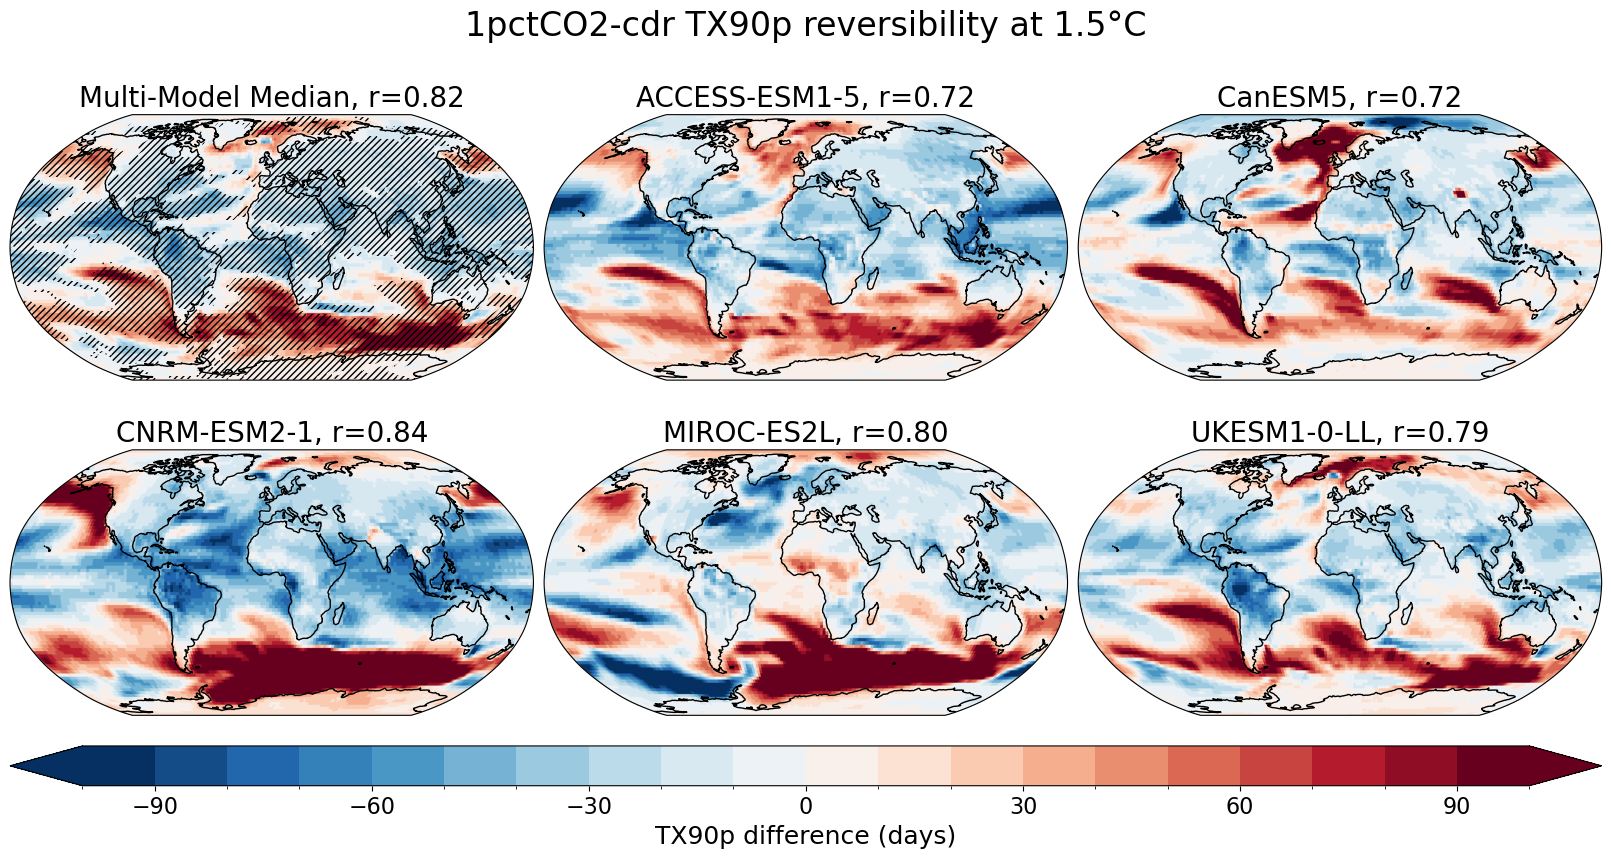

In [25]:
thr = 'sigma2'
r = corrs['heat']['freq vs tx90p']
titles = {m: f"{pl.display_name(m)}, r={float(r[m].sel(threshold=thr)):.2f}" for m in r}

fig, axes = pl.plot_gwl_diff(
    diffs['tx90p']['diff'],
    '1pctCO2-cdr',
    varname='tx90p',
    gwl=1.5,
    levels=np.linspace(-100, 100, 21),
    cmap=cm.RdBu_r,
    agreement=diffs['tx90p']['agreement'],
    cbar_label='TX90p difference (days)',
    figsize=(16, 8),
    suptitle='1pctCO2-cdr TX90p reversibility at 1.5°C',
    titles=titles,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S6.jpg',
)

Saved: /g/data/if69/sc1326/repos/cdrmip_extremes/figures/supplementary/figure_S7.jpg


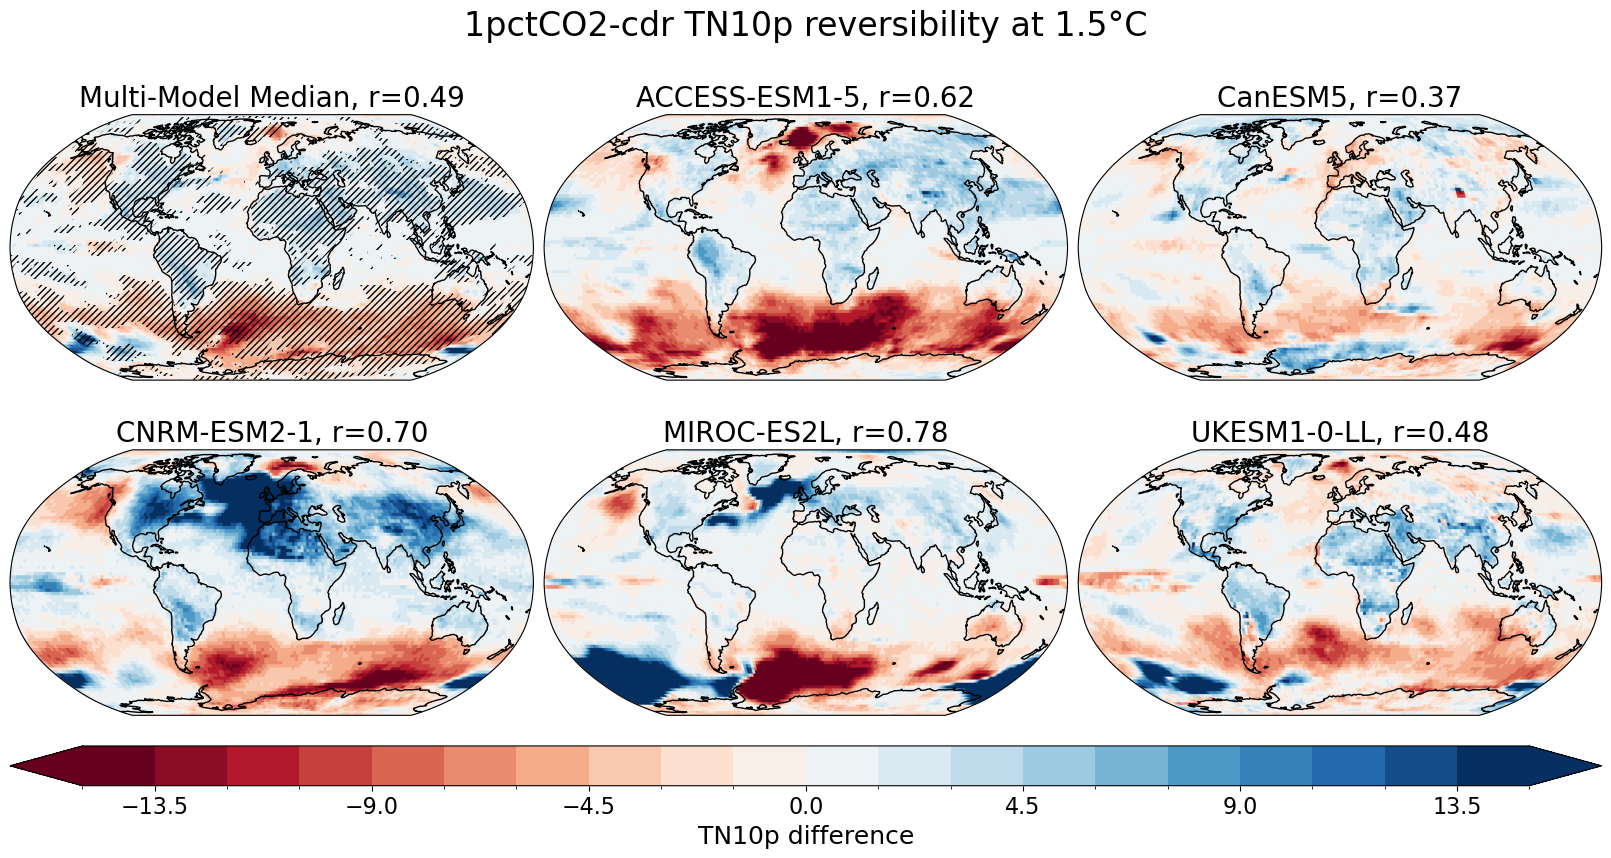

In [26]:
thr = 'sigma2'
r = corrs['cold']['freq vs tn10p']
titles = {m: f"{pl.display_name(m)}, r={float(r[m].sel(threshold=thr)):.2f}" for m in r}
fig, axes = pl.plot_gwl_diff(
    diffs['tn10p']['diff'],
    '1pctCO2-cdr',
    varname='tn10p',
    gwl=1.5,
    levels=np.linspace(-15,15,21),
    cmap=cm.RdBu,
    agreement = diffs['tn10p']['agreement'],
    cbar_label = 'TN10p difference',
    figsize=(16, 8),
    suptitle = '1pctCO2-cdr TN10p reversibility at 1.5°C',
    titles=titles,
    fig_dir=FIG_DIR,
    folder='supplementary',
    file_name='figure_S7.jpg'
)

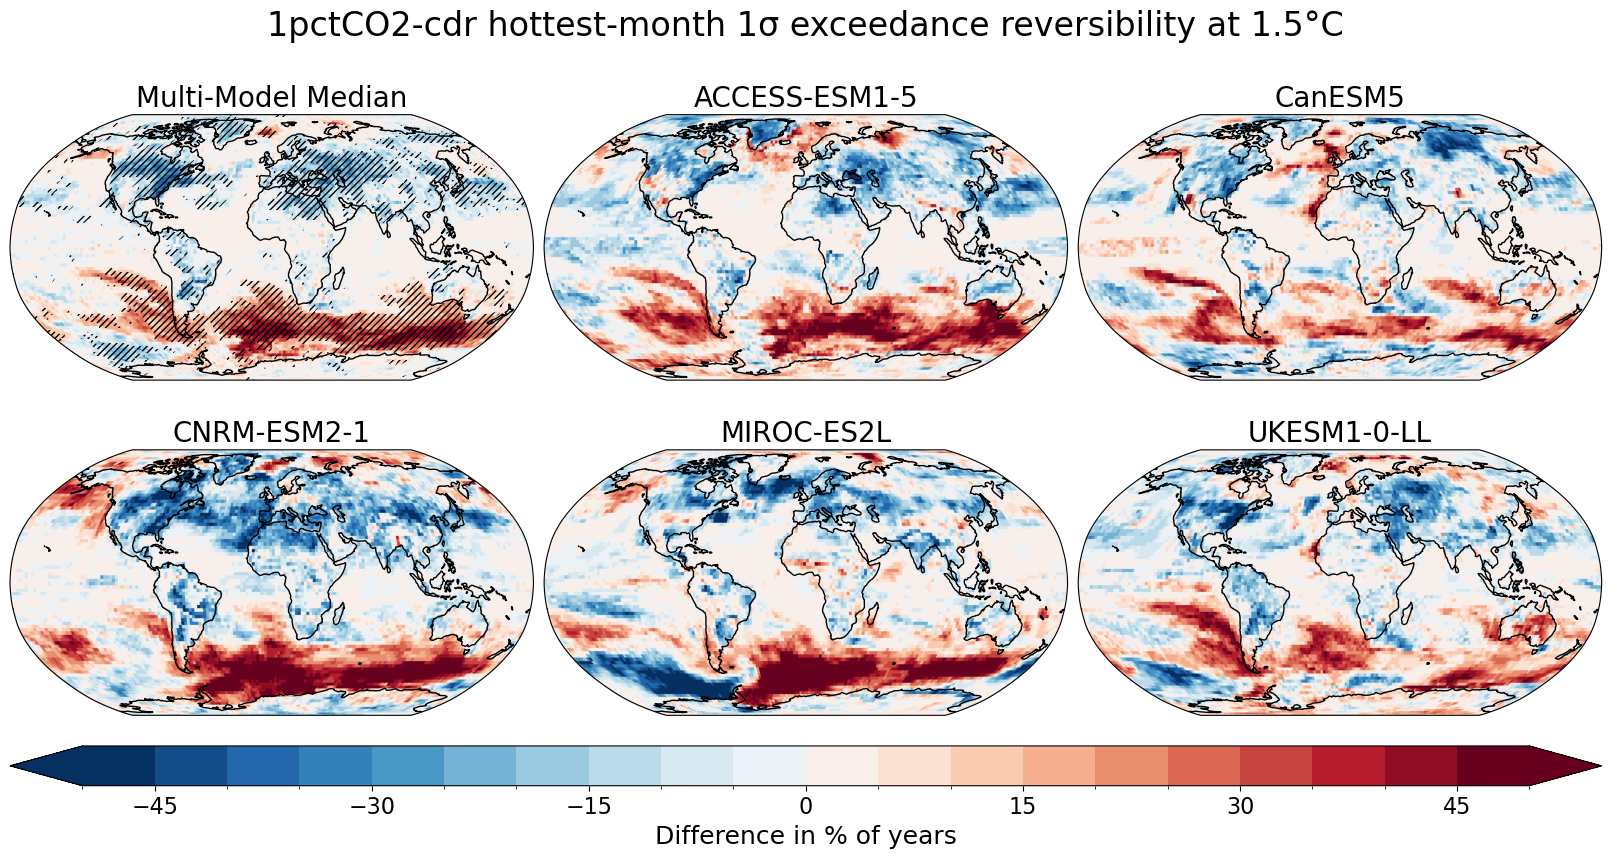

In [64]:
tp_models = ['ACCESS-ESM1-5', 'CanESM5', 'CNRM-ESM2-1', 'MIROC-ES2L', 'UKESM1-0-LL']

mon_tree = {m: {expt: differences[m][expt]['heat']} for m in tp_models}
mon_agree = stats.calc_agreement(mon_tree, expt=expt)   # before adding the median
mon_tree = utils.reduce_models(mon_tree)                 # adds 'multi_model_median'

fig, axes = pl.plot_gwl_diff(
    mon_tree,
    expt,
    varname='sigma1',
    gwl=1.5,
    levels=np.linspace(-50, 50, 21),
    cmap=cm.RdBu_r,
    agreement=mon_agree,
    cbar_label='Difference in % of years',
    figsize=(16, 8),
    suptitle='1pctCO2-cdr hottest-month 1σ exceedance reversibility at 1.5°C',
)

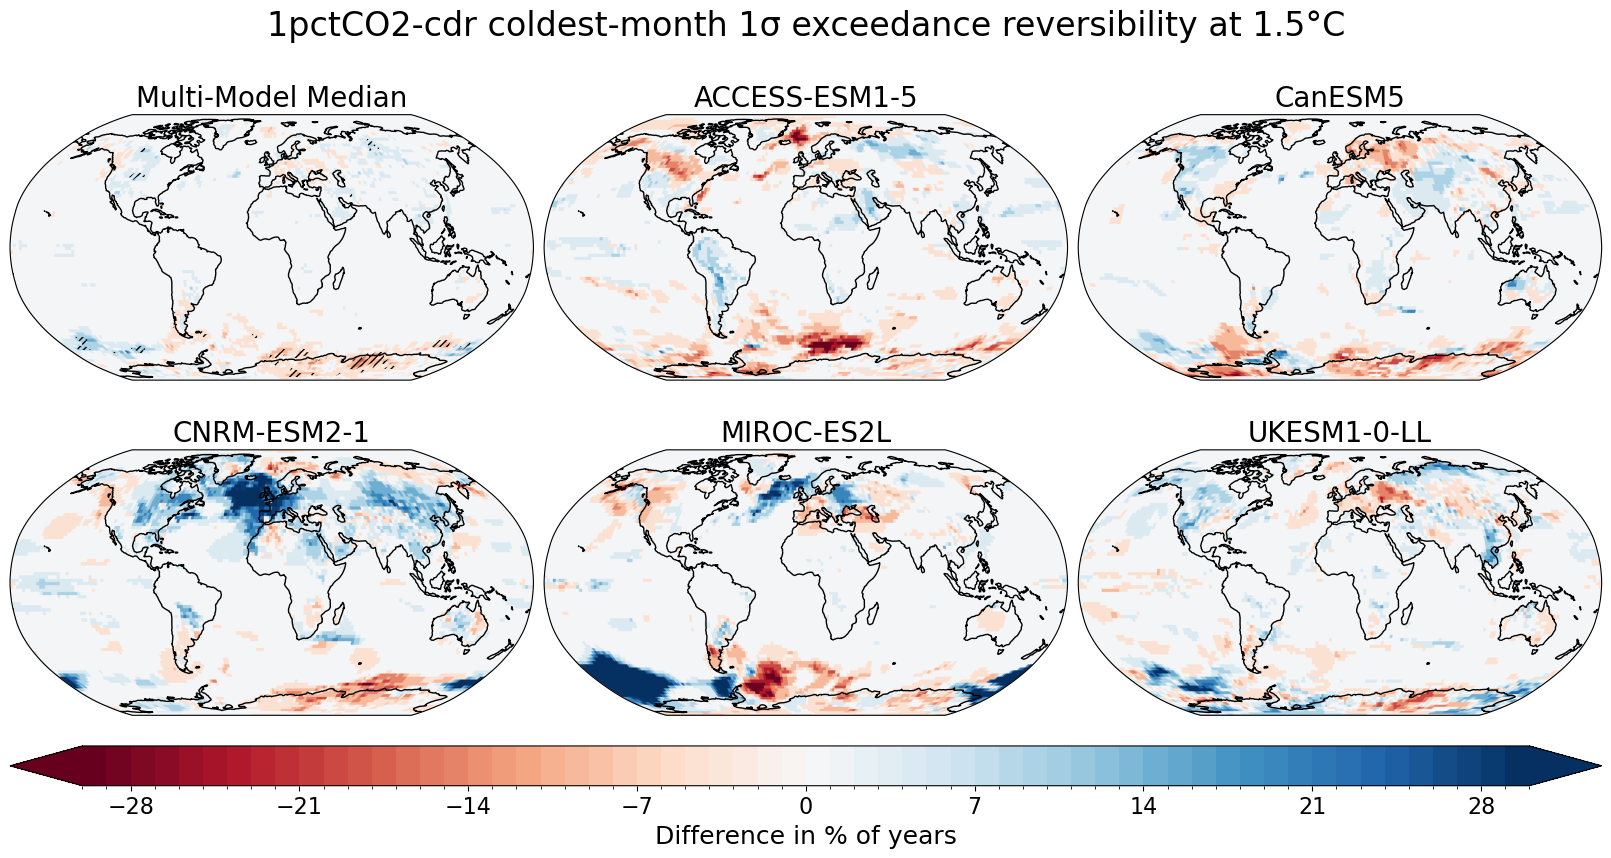

In [68]:
mon_tree = {m: {expt: differences[m][expt]['cold']} for m in tp_models}
mon_agree = stats.calc_agreement(mon_tree, expt=expt)   # before adding the median
mon_tree = utils.reduce_models(mon_tree)                 # adds 'multi_model_median'

fig, axes = pl.plot_gwl_diff(
    mon_tree,
    expt,
    varname='sigma3',
    gwl=1.5,
    levels=np.linspace(-30, 30, 61),
    cmap=cm.RdBu,
    agreement=mon_agree,
    cbar_label='Difference in % of years',
    figsize=(16, 8),
    suptitle='1pctCO2-cdr coldest-month 1σ exceedance reversibility at 1.5°C',
)

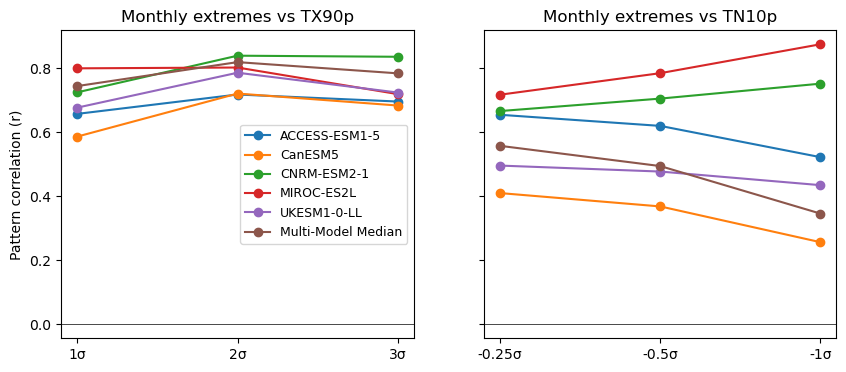

In [63]:
cases = [('TX90p', tx90p_corrs, ['1σ', '2σ', '3σ']),
         ('TN10p', tn10p_corrs, ['-0.25σ', '-0.5σ', '-1σ'])]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, (name, corrs, xlabels) in zip(axes, cases):
    for m, r in corrs.items():
        ax.plot(xlabels, r.sel(threshold=['sigma1', 'sigma2', 'sigma3']), 'o-', label=pl.display_name(m))
    ax.set_title(f'Monthly extremes vs {name}')
    ax.axhline(0, c='k', lw=0.5)
axes[0].set_ylabel('Pattern correlation (r)')
axes[0].legend(fontsize=9)

## Land surface

In [89]:
land = (sftlf > 50).reset_coords(drop=True)   # CMIP6 sftlf is in %, check sftlf.max()

def pattern_corr(a, b, mask=None):
    a, b = a.reset_coords(drop=True), b.reset_coords(drop=True)
    if mask is not None:
        a, b = a.where(mask), b.where(mask)
    w = np.cos(np.deg2rad(b.lat)).broadcast_like(b)
    return xr.corr(a, b, dim=['lat', 'lon'], weights=w).squeeze('gwl', drop=True).compute().drop_attrs()

corrs_land = {
    ext: {f'{a} vs {b}': {m: pattern_corr(F[a][m][expt], F[b][m][expt], mask=land) for m in F[a]}
          for a, b in pairs[ext]}
    for ext, F in fields.items()
}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

In [91]:
corrs_land['cold']

{'freq vs tn10p': {'ACCESS-ESM1-5': <xarray.DataArray (threshold: 3)> Size: 24B
  array([0.43455473, 0.38138707, 0.31707994])
  Coordinates:
    * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
  'CanESM5': <xarray.DataArray (threshold: 3)> Size: 24B
  array([0.33456061, 0.30482921, 0.23535093])
  Coordinates:
    * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
  'CNRM-ESM2-1': <xarray.DataArray (threshold: 3)> Size: 24B
  array([0.50933924, 0.52148545, 0.55389949])
  Coordinates:
    * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
  'MIROC-ES2L': <xarray.DataArray (threshold: 3)> Size: 24B
  array([0.29427562, 0.30040566, 0.28847736])
  Coordinates:
    * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
  'UKESM1-0-LL': <xarray.DataArray (threshold: 3)> Size: 24B
  array([0.29534281, 0.28211655, 0.20811234])
  Coordinates:
    * threshold  (threshold) object 24B 'sigma1' 'sigma2' 'sigma3',
  'multi_model_median': <xarray.Data